# Inverse design of a two-fin **full-scattering** exceptional-point candidate

This notebook optimizes the **complete, power-normalized complex $4\times4$ scattering matrix** of a periodic two-fin unit cell, using a differentiable TORCWA solver on CUDA. The existing `TwoFin_Engine.ipynb` remains the **lossless forward-model/validation** notebook.

**Physical feasibility comes first.** With passive, *lossless*, subwavelength, four-channel scattering, $S^\dagger S=I$. A unitary (normal) matrix cannot be defective; therefore the original lossless two-fin structure **cannot have a full-$S$ scattering EP**. Here we allow controlled material absorption $n_\mathrm{fin}=n'+i\kappa$ ($e^{-i\omega t}$ convention), with $\kappa\ge0$. This is an **effective lossy-material design exploration, not a claim that pure Al₂O₃ has that loss**. A real material and process must subsequently be identified.

An EP needs **both** a repeated eigenvalue **and** a defective eigenbasis. The optimization objective uses the differentiable characteristic-polynomial discriminant, a non-normality requirement, passivity/reciprocity checks, and fabrication penalties. The strict final diagnostics inspect eigenvector alignment, singular-value rank, isolation of other eigenvalues, numerical convergence, and eigenvalue switching on a parameter loop. Repeated eigenvalues alone are **not** an EP.

**Phase convention**: output channel order `(bottom x, bottom y, top x, top y)`, $e^{-i\omega t}$; complex transmission and common Jones phase are retained. **Fixed reference planes** at $z_b=-0.52$ µm and $z_t=1.05$ µm are used for every design. For scattering eigenvalues, shifting the planes generally transforms $S\mapsto DSD$ (not similarity), so the reported scattering EP depends on this experimental port convention.

**Execution**: this notebook actually runs expensive CUDA simulations when its `RUN_*` switches are enabled. No numerical EP is claimed until your hardware has run and passed the gates. Keep the inverse-design search separate from final convergence/validation.

## 1 · Runtime, physical model, and computational budget

In [ ]:
# Shared engines live in ../core (see ../PROJECTS.md). Run with the notebook folder as cwd.
import sys; from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / 'core').resolve()))

In [ ]:
from pathlib import Path
from dataclasses import replace
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from twofin import Config, draw_geometry, write_gds
from engine_rcwa import Settings as RCWASettings, solve as rcwa_solve, solve_torch
from engine_inverse import (FIXED_PORTS, KEYS, BOUNDS, sobol_screen, multistart,
                            candidate_to_config, numpy_to_params, load_checkpoint,
                            save_checkpoint)
from engine_ep import (ep_diagnostics, print_ep_report, track_eigenvalues,
                       discriminant_torch, nonnormality_torch)

OUT=Path('results/ep_design'); OUT.mkdir(parents=True,exist_ok=True)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cuda.matmul.allow_tf32=False  # Avoid unrequested reduced precision
np.random.seed(11); torch.manual_seed(11)
base_cfg=Config(wavelength=0.633, period=0.400, n_fin=1.85, n_fin_kappa=0.009)

# GPU-first defaults; keep the CPU path restricted to the smoke test.
RUN_GRADIENT_TEST=True
RUN_OPTIMIZATION=(DEVICE=='cuda')
FORCE_OPTIMIZATION=True    # Reuse saved candidate unless explicitly restarting
RUN_CONVERGENCE=(DEVICE=='cuda')
RUN_ENCIRCLING=True     # Additional ~32 independent RCWA solves when enabled
RUN_PARAM_SCAN=True      # Additional 25 RCWA solves to map the EP neighbourhood
RUN_HARD_EDGE_POLISH=True  # Optional <=50 costly binary RCWA evaluations
N_SCREEN=64              # Sobol candidates at low order
KEEP_STARTS=8
N_ADAM_LOW=55
N_ADAM_HIGH=75

screen_settings=RCWASettings(order=3,raster=128,samples=3,device=DEVICE)
refine_settings=RCWASettings(order=5,raster=160,samples=3,device=DEVICE)
print('TORCH',torch.__version__,'device=',DEVICE)
if DEVICE=='cuda':
    print('GPU:',torch.cuda.get_device_name(0))
else:
    print('No CUDA found. Optimization is disabled by default; use an A6000 for the full search.')
print('Fixed scattering reference planes (µm):',FIXED_PORTS)
print('Free physical parameters:',', '.join(KEYS))

TORCH 2.14.1 device= cuda
GPU: NVIDIA RTX A6000
Fixed scattering reference planes (µm): (-0.52, 1.05)
Free physical parameters: L1, W1, theta1, x1, y1, L2, W2, theta2, x2, y2, height, kappa


## 2 · Why the original lossless design has no full-$S$ EP

The complete scattering matrix is four-dimensional because there are two polarizations per side. A genuine **second-order full-$S$ EP** has one repeated eigenvalue $\lambda_\star$ with **algebraic multiplicity 2** and **geometric multiplicity 1**. Locally it has a Jordan block $\begin{psmallmatrix}\lambda_\star&1\\0&\lambda_\star\end{psmallmatrix}$ in a suitable *non-orthogonal* basis. The EP is compatible with a passive reciprocal **lossy** four-port, but **incompatible with a lossless unitary full four-port**.

An EP of a $2\times2$ transmission Jones block is a different concept: such a block may be defective even if the complete $4\times4$ scattering operator remains unitary. We explicitly optimize and diagnose the **full** matrix, not a selected subblock.

The design variables are independent lengths, widths, orientations and planar centers of both fins, their common height, and a passive extinction coefficient $\kappa$. The two fins can overlap (the permittivity is the Boolean union); a soft penalty prevents unit-cell boundary crossing.

In [2]:
print('Parameter bounds (µm except angles/radians and kappa):')
for key, limits in BOUNDS.items():
    print(f'{key:7s}: {limits}')
print('Fixed wavelength (µm):',base_cfg.wavelength)

Parameter bounds (µm except angles/radians and kappa):
L1     : (0.09, 0.34)
W1     : (0.035, 0.15)
theta1 : (-1.5707963267948966, 1.5707963267948966)
x1     : (-0.13, 0.13)
y1     : (-0.13, 0.13)
L2     : (0.09, 0.34)
W2     : (0.035, 0.15)
theta2 : (-1.5707963267948966, 1.5707963267948966)
x2     : (-0.13, 0.13)
y2     : (-0.13, 0.13)
height : (0.15, 0.5)
kappa  : (0.005, 0.22)
Fixed wavelength (µm): 0.633


## 3 · Essential autograd smoke test (small RCWA order)

Before spending GPU time, verify a **nonzero, finite gradient** from TORCWA with respect to one angle and compare against central finite differences **of the same soft geometry**, away from eigenvalue collisions. This tests differentiability of the actual full complex-$S$ pipeline; it does **not** validate the electromagnetic accuracy.

In [3]:
initial={k:(lo+hi)/2 for k,(lo,hi) in BOUNDS.items()}
initial.update(theta1=0.18,theta2=1.10,x1=-0.045,y1=-0.055,
               x2=0.055,y2=0.042,kappa=0.065)
smoke=RCWASettings(order=2,raster=96,samples=3,device=DEVICE)
if RUN_GRADIENT_TEST:
    p=numpy_to_params(initial,device=DEVICE)
    p['theta1']=p['theta1'].detach().clone().requires_grad_(True)
    S=solve_torch(base_cfg,p,smoke,ports=FIXED_PORTS)
    # Non-spectral scalar objective; low risk of repeated-eigenvalue gradients.
    observable=torch.real(S[2,0])+torch.abs(S[3,1])**2
    derivative=torch.autograd.grad(observable,p['theta1'])[0].item()
    with torch.no_grad():
        delta=1e-3
        plus=dict(p); minus=dict(p)
        plus['theta1']=p['theta1'].detach()+delta
        minus['theta1']=p['theta1'].detach()-delta
        Sp=solve_torch(base_cfg,plus,smoke,ports=FIXED_PORTS)
        Sm=solve_torch(base_cfg,minus,smoke,ports=FIXED_PORTS)
        obs=lambda A:float((torch.real(A[2,0])+torch.abs(A[3,1])**2).cpu())
        finite_difference=(obs(Sp)-obs(Sm))/(2*delta)
    rel_error=abs(derivative-finite_difference)/max(1e-4,abs(finite_difference))
    print(f'dS-based observable/d(theta1): autograd={derivative:.6g}, '
          f'finite-difference={finite_difference:.6g}; rel err={rel_error:.3g}')
    assert np.isfinite(derivative) and abs(derivative)>1e-9, 'Missing or zero gradient'
    assert rel_error < 0.2, 'TORCWA gradient smoke test failed: do not optimize yet'
else:
    print('Gradient smoke test disabled explicitly.')

dS-based observable/d(theta1): autograd=-0.0214151, finite-difference=-0.0207424; rel err=0.0324


## 4 · Coarse global exploration → bounded Adam local searches

This is a nonconvex continuous optimization problem. We **do not claim a formal NP-hardness result** for this particular parameterization. An exhaustive genetic algorithm with a costly electromagnetic solver is unattractive. Instead: (1) low-order randomized **Sobol** screening, (2) several bounded **Adam** runs, (3) refinement at higher RCWA order, and (4) hard-edge/high-order checks. The smooth discriminant loss intentionally *does not* equate a mere degeneracy with a verified EP.

Early stopping in Adam means **optimization plateau**, not proof of an EP. A scientifically valid stop requires the later spectral and convergence gates to pass.

In [4]:
checkpoint=OUT/'best_gradient_candidate.npz'
if RUN_OPTIMIZATION and (FORCE_OPTIMIZATION or not checkpoint.exists()):
    t0=time.perf_counter()
    seeds,screen_log=sobol_screen(base_cfg,screen_settings,
                                  candidates=N_SCREEN,keep=KEEP_STARTS,seed=11)
    print('Sobol phase seconds:',round(time.perf_counter()-t0,2))
    low=multistart(base_cfg,screen_settings,seeds,iterations=N_ADAM_LOW,
                   lr=0.065,edge_um=0.009)
    print('Best low-order loss:',low[0]['loss'])
    high_starts=[r['params'] for r in low[:2]]
    high=multistart(base_cfg,refine_settings,high_starts,
                    iterations=N_ADAM_HIGH,lr=0.025,edge_um=0.005)
    best=high[0]
    save_checkpoint(checkpoint,best,extra={'screen_order':3,'refine_order':5,
                                         'fixed_ports':FIXED_PORTS})
    print('Saved:',checkpoint)
elif checkpoint.exists():
    best=load_checkpoint(checkpoint)
    print('Loaded existing candidate:',checkpoint)
else:
    best=None
    print('No CUDA / checkpoint; run optimization on the workstation to populate these figures.')

Loaded existing candidate: results/ep_design/best_gradient_candidate.npz


## 4b · Optional local polish on hard-edged polygons

In [5]:
if best is not None and RUN_HARD_EDGE_POLISH:
    from engine_inverse import polish_hard_edges
    hard_polished=polish_hard_edges(base_cfg,best['params'],refine_settings,
                                  max_evaluations=50)
    print('Binary-geometry local refinement result:', hard_polished['loss'])
    print_ep_report(hard_polished['S'],label='Hard-edge local polish')
    # Keep this result separately to preserve provenance of the Adam history.
    save_checkpoint(OUT/'binary_polished_candidate.npz',
                    {**hard_polished,'history':[]})
    best={**best,'params':hard_polished['params'],'S':hard_polished['S'],
          'loss':hard_polished['loss']}
else:
    print('No hard-edge local polish (optional).')

Binary RCWA evaluation 10: objective -22.8688
Binary RCWA evaluation 20: objective -17.3768
Binary RCWA evaluation 30: objective -22.5033
Binary RCWA evaluation 40: objective -22.8923
Binary RCWA evaluation 50: objective -22.9111
Binary-geometry local refinement result: -22.911125601973502

Hard-edge local polish: full 4x4 scattering EP diagnostics
Nearest/coalescing candidate: eigenvalues 2,3
  normalized eigenvalue gap: 3.279e-04 (target < 1.0e-03)
  eigenvector overlap: 0.552092 (target > 0.995)
  second-smallest SV at mean eigenvalue: 3.049e-04
  distance from other eigenvalues: 1.910e+00
  non-normality: 8.946e-02
  reciprocity residual: 7.223e-05
  largest output/input power gain: 0.765553
  Screening: NOT A VALIDATED FULL-S EP


## 5 · Optimized geometry and convergence of the objective

Best differentiable search objective: -22.911125601973502
L1     : +0.14905
W1     : +0.14784
theta1 : +60.2495 deg
x1     : +0.04717
y1     : -0.08985
L2     : +0.10134
W2     : +0.09327
theta2 : -1.8983 deg
x2     : -0.12699
y2     : +0.10560
height : +0.39544
kappa  : +0.21892


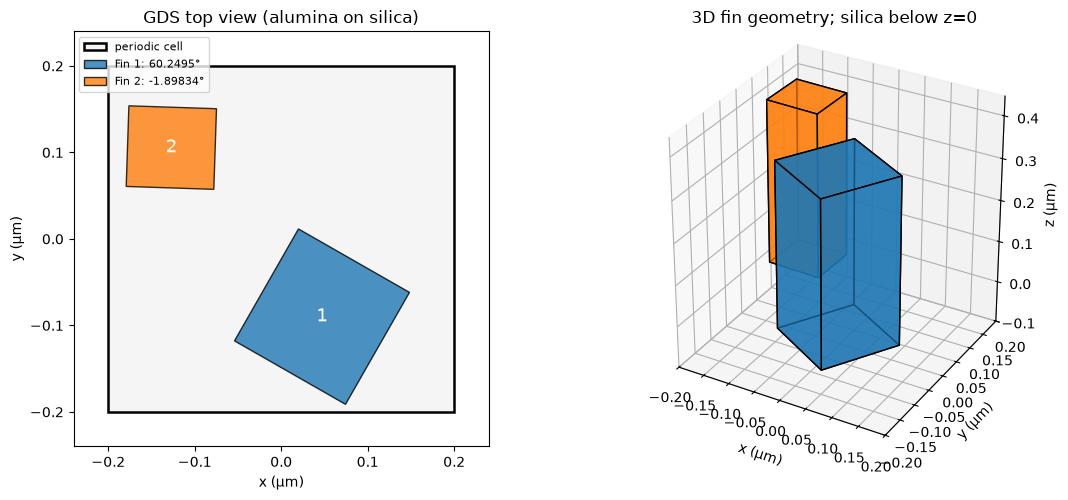

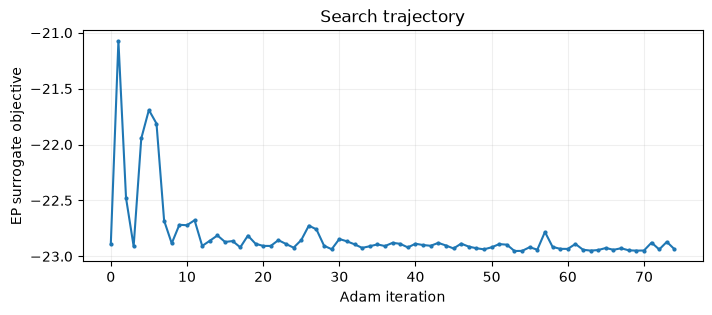

In [6]:
if best is not None:
    physical=best['params']
    print('Best differentiable search objective:',best['loss'])
    for key in KEYS:
        v=physical[key]
        print(f'{key:7s}: {np.rad2deg(v):+.4f} deg' if 'theta' in key else f'{key:7s}: {v:+.5f}')
    try:
        manufactured=candidate_to_config(base_cfg,physical)
        fig=draw_geometry(manufactured,OUT/'candidate_geometry.png')
        plt.show()
        write_gds(manufactured,OUT/'ep_candidate.gds')
    except ValueError as exc:
        manufactured=None
        print('FABRICATION CONSTRAINT FAILURE:',exc)
    if best['history']:
        h=best['history']
        fig,ax=plt.subplots(figsize=(8,3))
        ax.plot([v['iteration'] for v in h],[v['loss'] for v in h],'-o',markersize=2)
        ax.set(xlabel='Adam iteration',ylabel='EP surrogate objective',title='Search trajectory')
        ax.grid(alpha=.2);plt.show()
else:
    manufactured=None

## 6 · Full-$S$ Jordan diagnostics, power balance, and common phase

We report all four complex eigenvalues. For each candidate pair, the diagnostic uses the normalized eigenvalue separation, **$|\langle v_i,v_j\rangle|$**, smallest and second-smallest singular values of $S-\bar\lambda I$, and separation from the two other eigenvalues. A genuine order-two EP has one eigenvector; a regular degeneracy has two. We also screen reciprocity and passivity. The common Jones phase remains accessible at any chosen fixed ports via $\arg\det(T_{21})/2\pmod\pi$; polarization-resolved transmission phases retain full $2\pi$ information.


Soft-edge search: full 4x4 scattering EP diagnostics
Nearest/coalescing candidate: eigenvalues 2,3
  normalized eigenvalue gap: 3.279e-04 (target < 1.0e-03)
  eigenvector overlap: 0.552092 (target > 0.995)
  second-smallest SV at mean eigenvalue: 3.049e-04
  distance from other eigenvalues: 1.910e+00
  non-normality: 8.946e-02
  reciprocity residual: 7.223e-05
  largest output/input power gain: 0.765553
  Screening: NOT A VALIDATED FULL-S EP


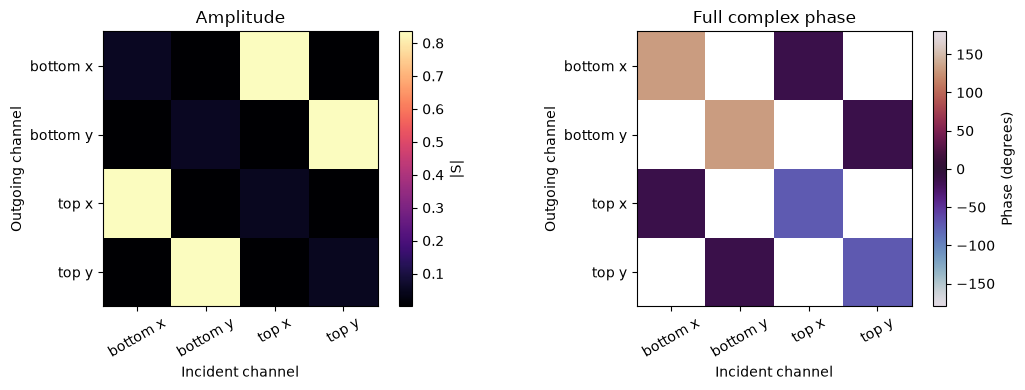

Forward transmission Jones matrix: [[ 8.11068706e-01-2.00877261e-01j -6.98903718e-05-1.92684651e-04j]
 [-6.77182669e-05-1.56302558e-04j  8.10981020e-01-2.00857854e-01j]]
det-based common phase (mod 180 deg): -13.910597387292704
Transmitted xx/yy phases (deg): -13.910520104490466 -13.910673902374667


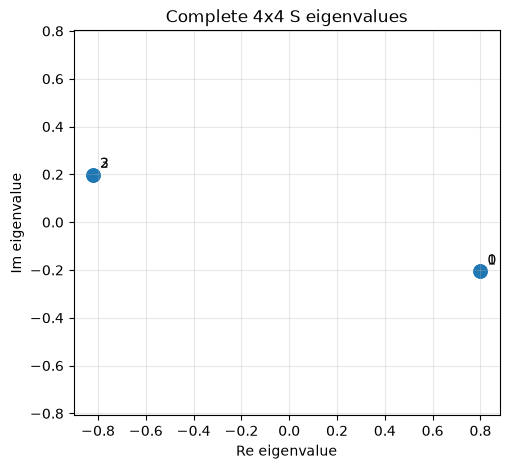

In [7]:
if best is not None:
    S_best=np.asarray(best['S'])
    search_diag,search_near=print_ep_report(S_best,label='Soft-edge search',gap_tol=1e-3)
    labels=['bottom x','bottom y','top x','top y']
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    im=ax[0].imshow(abs(S_best),cmap='magma');fig.colorbar(im,ax=ax[0],label='|S|')
    phase=np.where(abs(S_best)>0.02,np.rad2deg(np.angle(S_best)),np.nan)
    im=ax[1].imshow(phase,cmap='twilight',vmin=-180,vmax=180)
    fig.colorbar(im,ax=ax[1],label='Phase (degrees)')
    for a in ax:
        a.set(xticks=range(4),yticks=range(4),xticklabels=labels,yticklabels=labels,
              xlabel='Incident channel',ylabel='Outgoing channel')
        a.tick_params(axis='x',labelrotation=30)
    ax[0].set_title('Amplitude');ax[1].set_title('Full complex phase')
    fig.tight_layout();plt.show()
    T=S_best[2:,:2]
    print('Forward transmission Jones matrix:',T)
    print('det-based common phase (mod 180 deg):',np.angle(np.linalg.det(T),deg=True)/2)
    print('Transmitted xx/yy phases (deg):',np.angle(T[0,0],deg=True),np.angle(T[1,1],deg=True))
    e=search_diag['eigenvalues']
    fig,ax=plt.subplots(figsize=(5.5,5))
    ax.scatter(e.real,e.imag,s=90)
    for k,v in enumerate(e): ax.annotate(str(k),(v.real,v.imag),xytext=(5,5),textcoords='offset points')
    ax.set(xlabel='Re eigenvalue',ylabel='Im eigenvalue',title='Complete 4x4 S eigenvalues')
    ax.set_aspect('equal',adjustable='datalim');ax.grid(alpha=.3);plt.show()

## 6b · Coalescing four-channel eigenvectors

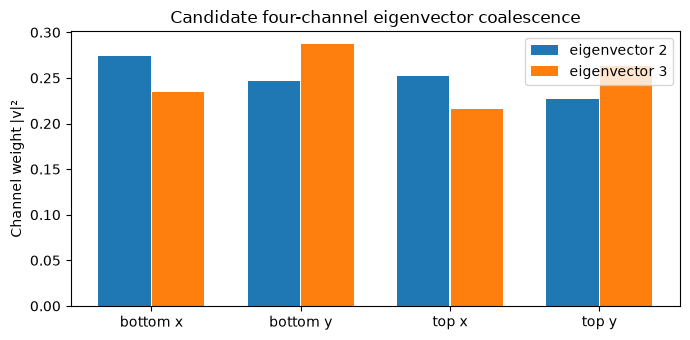

Complex eigenvector overlap: 0.55209180755779


In [8]:
if best is not None:
    i,j=search_diag['best']['pair']
    vectors=search_diag['eigenvectors']
    chans=['bottom x','bottom y','top x','top y']
    fig,ax=plt.subplots(figsize=(7,3.5))
    x=np.arange(4)
    ax.bar(x-0.18,np.abs(vectors[:,i])**2,width=.35,label=f'eigenvector {i}')
    ax.bar(x+0.18,np.abs(vectors[:,j])**2,width=.35,label=f'eigenvector {j}')
    ax.set(xticks=x,xticklabels=chans,ylabel='Channel weight |v|²',
           title='Candidate four-channel eigenvector coalescence')
    ax.legend();fig.tight_layout();plt.show()
    print('Complex eigenvector overlap:',abs(np.vdot(vectors[:,i],vectors[:,j])))

## 7 · Hard-edge RCWA and Fourier-order convergence **(required for acceptance)**

The differentiable raster is deliberately smoothed; fabrication requires sharp, binary material boundaries. We therefore build the actual polygon union via the original `Config` and run **independent, non-differentiable** RCWA at increasing Fourier orders with fixed experimental ports. In particular, neither a tiny discriminant at low order nor visually touching eigenvalues constitutes success. Every converged complex matrix should agree within your selected error tolerance.

In [9]:
hard_results={}
if manufactured is not None and RUN_CONVERGENCE:
    import hashlib
    cache_path=OUT/'hard_edge_order_convergence.npz'
    key=hashlib.sha256(json.dumps(best['params'],sort_keys=True).encode()).hexdigest()[:16]
    if cache_path.exists() and not FORCE_OPTIMIZATION:
        with np.load(cache_path,allow_pickle=False) as f:
            if 'parameter_hash' in f.files and str(f['parameter_hash'])==key:
                hard_results={int(o):S for o,S in zip(f['orders'],f['matrices'])}
                print('Reusing converged hard-edge RCWA cache:',cache_path)
    for order in (5,7,9):
        if order in hard_results:
            continue
        settings=RCWASettings(order=order,raster=224 if order>=7 else 160,
                              samples=5,device=DEVICE,precision='complex64')
        t0=time.perf_counter()
        run=rcwa_solve(manufactured,settings,ports=FIXED_PORTS)
        hard_results[order]=run['S']
        print(f'order {order}: {time.perf_counter()-t0:.1f}s, '
              f'max power gain {ep_diagnostics(run["S"])["max_power_gain"]:.5f}')
        print_ep_report(run['S'],label=f'Hard-edge order {order}')
    for a,b in zip(list(hard_results)[:-1],list(hard_results)[1:]):
        difference=float(np.max(np.abs(hard_results[a]-hard_results[b])))
        print(f'Max absolute complex-S difference {a}→{b}: {difference:.4e}')
    np.savez_compressed(OUT/'hard_edge_order_convergence.npz',
                        orders=np.array(list(hard_results)),
                        matrices=np.array(list(hard_results.values())),
                        fixed_ports=np.array(FIXED_PORTS),parameter_hash=key)
elif best is not None:
    print('Hard-edge validation not run: candidate remains UNVERIFIED.')

Reusing converged hard-edge RCWA cache: results/ep_design/hard_edge_order_convergence.npz
Max absolute complex-S difference 5→7: 1.1231e-02
Max absolute complex-S difference 7→9: 7.1774e-03


## 8 · Parameter-loop encircling and eigenvalue sheet exchange (optional, recommended)

Perturb **two independent physical parameters**, $\theta_1$ and $\kappa$, around the optimized geometry. A second-order EP is associated with eigenvalue exchange after encircling it. Eigenvalues are continued by a minimum-distance assignment, not sorted independently at each step. A loop may fail to encircle an EP even when the central point is close; verify stability against loop radius and resolution. The plot is an independent test, **not** an automatic certificate.

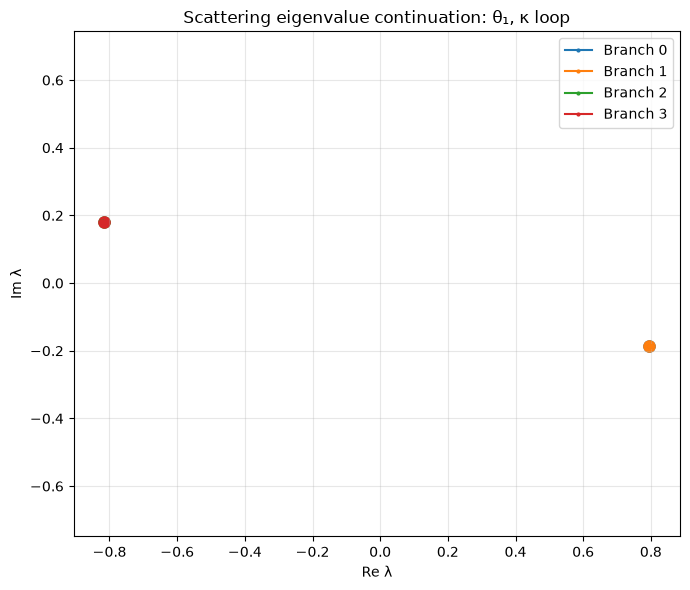

Closed-loop eigenvalue permutation (start index -> final tracked branch):
{0: 0, 1: 1, 2: 2, 3: 3}
Small loops may fail to surround the EP: repeat for multiple radii.


In [10]:
if best is not None and RUN_ENCIRCLING:
    from scipy.optimize import linear_sum_assignment
    center=best['params']; samples=32
    theta_radius=np.deg2rad(2.0)
    kappa_radius=0.012
    circle=np.linspace(0,2*np.pi,samples+1)
    loop=[]
    loop_settings=RCWASettings(order=5,raster=160,device=DEVICE)
    for t in circle:
        trial=dict(center)
        trial['theta1']=float(np.clip(center['theta1']+theta_radius*np.cos(t),*BOUNDS['theta1']))
        trial['kappa']=float(np.clip(center['kappa']+kappa_radius*np.sin(t),*BOUNDS['kappa']))
        with torch.no_grad():
            Sloop=solve_torch(base_cfg,numpy_to_params(trial,device=DEVICE),
                              loop_settings,edge_um=0.005,ports=FIXED_PORTS)
            loop.append(Sloop.cpu().numpy())
    branches=track_eigenvalues(loop)
    fig,ax=plt.subplots(figsize=(7,6))
    for i in range(4):
        ax.plot(branches[:,i].real,branches[:,i].imag,'o-',ms=2,label=f'Branch {i}')
        ax.scatter(branches[0,i].real,branches[0,i].imag,s=65)
    ax.set(xlabel='Re λ',ylabel='Im λ',title='Scattering eigenvalue continuation: θ₁, κ loop')
    ax.legend();ax.set_aspect('equal',adjustable='datalim');ax.grid(alpha=.3)
    fig.tight_layout();plt.show()
    initial_e=branches[0]; final_e=branches[-1]
    ri,ci=linear_sum_assignment(abs(initial_e[:,None]-final_e[None,:]))
    print('Closed-loop eigenvalue permutation (start index -> final tracked branch):')
    print({int(k):int(ci[k]) for k in ri})
    print('Small loops may fail to surround the EP: repeat for multiple radii.')
else:
    print('Encircling disabled. Set RUN_ENCIRCLING=True to investigate sheet exchange.')

## 8b · Optional local two-parameter EP map

The normalized minimum eigenvalue separation is evaluated around the candidate in $(\theta_1,\kappa)$ space and shown on a logarithmic map. A *near-zero* separation in such a map identifies a candidate singular point but does not establish defectiveness. Combine it with the eigenvector/rank checks above and a stable encircling test.

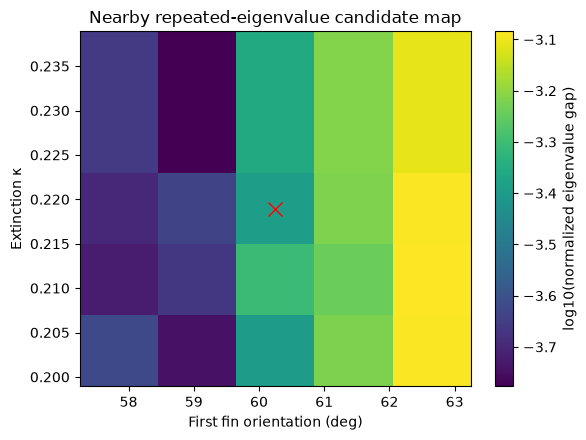

In [11]:
if best is not None and RUN_PARAM_SCAN:
    scan_settings=RCWASettings(order=5,raster=160,device=DEVICE)
    radii_angle=np.deg2rad(3.0)
    radii_loss=0.02
    theta_values=best['params']['theta1']+np.linspace(-radii_angle,radii_angle,5)
    k_values=best['params']['kappa']+np.linspace(-radii_loss,radii_loss,5)
    mesh=np.full((len(k_values),len(theta_values)),np.nan)
    for iy,k in enumerate(k_values):
        for ix,theta in enumerate(theta_values):
            trial=dict(best['params'])
            trial.update(theta1=float(np.clip(theta,*BOUNDS['theta1'])),
                         kappa=float(np.clip(k,*BOUNDS['kappa'])))
            with torch.no_grad():
                S=solve_torch(base_cfg,numpy_to_params(trial,device=DEVICE),
                              scan_settings,ports=FIXED_PORTS,edge_um=.005)
                diagnostics=ep_diagnostics(S.cpu().numpy())
                mesh[iy,ix]=diagnostics['best']['gap']
    fig,ax=plt.subplots(figsize=(6,4.5))
    image=ax.imshow(np.log10(np.maximum(mesh,1e-12)),origin='lower',aspect='auto',
       extent=[np.rad2deg(theta_values[0]),np.rad2deg(theta_values[-1]),
               k_values[0],k_values[-1]],cmap='viridis')
    ax.plot(np.rad2deg(best['params']['theta1']),best['params']['kappa'],
            marker='x',color='red',markersize=10)
    fig.colorbar(image,ax=ax,label='log10(normalized eigenvalue gap)')
    ax.set(xlabel='First fin orientation (deg)',ylabel='Extinction κ',
           title='Nearby repeated-eigenvalue candidate map')
    fig.tight_layout();plt.show()
else:
    print('Local parameter map disabled (optional).')

## 9 · Acceptance decision and outputs

A final **near-EP candidate** needs, at minimum: normalized eigenvalue gap $<10^{-3}$, eigenvector overlap $>0.995$, isolated other modes, rank-one nullspace (not rank-two), passive power gain $\le1.005$, reciprocity agreement, and **converged** hard-edge complex $S$. These are chosen screening tolerances, *not universal mathematical EP thresholds*. A strong EP claim also needs parameter-loop eigenvalue exchange and robustness under numerical precision, reference conventions, and fabrication variation. **No pass is invented when a criterion is missing.**

For a manufactured design, optical-material absorption must be physically realizable at 633 nm. Even if an ideal continuous-parameter design reaches an EP, fabrication only approximates the precise condition.

In [12]:
if best is not None:
    if hard_results:
        orders=list(hard_results)
        d,close=print_ep_report(hard_results[orders[-1]],label='Final hard-edge candidate')
        numerical_error=max(float(np.max(abs(hard_results[a]-hard_results[b])))
                            for a,b in zip(orders[:-1],orders[1:]))
        converged=(numerical_error<0.01)
        print('Complex-S convergence criterion (<0.01):',converged,
              '| observed:',numerical_error)
        print('CANDIDATE READY FOR LOOP TEST?' , bool(close and converged))
        if not(close and converged):
            print('RESULT: NO validated full-S scattering EP has been demonstrated.')
        else:
            print('RESULT: provisional near-EP; require encircling and independent checks.')
    else:
        print('RESULT: NOT VALIDATED — no hard-edge order-convergence data.')
    summary=dict(parameters=best['params'],wavelength_um=base_cfg.wavelength,
                 fixed_port_planes_um=list(FIXED_PORTS),
                 exploratory_loss=True,
                 status='unverified candidate' if not hard_results else 'see convergence output')
    (OUT/'candidate_manifest.json').write_text(json.dumps(summary,indent=2))
    print('Saved metadata:',OUT/'candidate_manifest.json')
else:
    print('No candidate: run optimization on CUDA, then run hard-edge verification.')


Final hard-edge candidate: full 4x4 scattering EP diagnostics
Nearest/coalescing candidate: eigenvalues 0,1
  normalized eigenvalue gap: 8.084e-04 (target < 1.0e-03)
  eigenvector overlap: 0.166812 (target > 0.995)
  second-smallest SV at mean eigenvalue: 4.779e-04
  distance from other eigenvalues: 1.914e+00
  non-normality: 8.454e-02
  reciprocity residual: 1.313e-04
  largest output/input power gain: 0.775026
  Screening: NOT A VALIDATED FULL-S EP
Complex-S convergence criterion (<0.01): False | observed: 0.01123137372802871
CANDIDATE READY FOR LOOP TEST? False
RESULT: NO validated full-S scattering EP has been demonstrated.
Saved metadata: results/ep_design/candidate_manifest.json


## Notes for the validation notebook and the next experiment

- `TwoFin_Engine.ipynb` continues to validate **lossless** Fresnel, reciprocal/unitary S, RCWA/FDTD agreement, field profiles, and matrix phase conventions. Its original settings are unchanged. The FDTD backend explicitly refuses nonzero $\kappa$ because its existing real-permittivity implementation would silently simulate the wrong material.
- The high-order **RCWA hard-edge** step here is the primary validation of any *lossy* EP candidate until a second loss-capable Maxwell solver is available. To validate an optimized nonidentical-fin geometry, `candidate_to_config` converts it into the updated `twofin.Config` with independent second-fin dimensions and GDS output.
- To demonstrate a *fabricated* EP, add measured complex optical constants, dimensional tolerances and material dispersion; optimize over multiple wavelengths and stochastic fabrication errors.
- A scattering EP is **not** interchangeable with a resonant-mode/QNM exceptional point. This notebook tests a fixed-real-frequency **full external scattering matrix**.